In [1]:
import pandas as pd

# Load the main analysis dataset
df = pd.read_csv("/kaggle/input/datasets/tanjimshaharia/bangla-stylo/final_bangla_stylometry_long_300.csv")

# Basic inspection
print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nCondition counts:")
print(df["condition"].value_counts())

print("\nMissing values:")
print(df.isna().sum())

print("\nFirst 6 rows:")
display(df.head(6))

Shape: (300, 4)

Columns:
['topic_id', 'topic', 'condition', 'text']

Condition counts:
condition
human                  100
llm                    100
machine_translation    100
Name: count, dtype: int64

Missing values:
topic_id     0
topic        0
condition    0
text         0
dtype: int64

First 6 rows:


,topic_id,topic,condition,text
0,1,Traffic congestion in Dhaka,human,এ কারণে যানজটের সৃষ্টি হয়। এ ছাড়া ফৌজদারহাট বা...
1,2,Air pollution in Bangladesh,human,বাতাসের এই মান ‘গ্রহণযোগ্য’ বা ‘মাঝারি’ মানের ...
2,3,Water pollution in Bangladesh,human,"গবেষণায় দেখা গেছে, কেরানীগঞ্জের হযরতপুর ইউনিয়ন..."
3,4,Plastic waste management,human,ফলে বিশ্বের অন্যান্য অনেক দেশের মতো সমুদ্রের প...
4,5,Flooding in Bangladesh,human,"এটি এখন ভারতের পশ্চিমবঙ্গ, ওডিশা ও বিহার রাজ্য..."
5,6,River erosion in Bangladesh,human,গেল কয়েক দিনের ভাঙনে নতুন ভারেঙ্গা ইউনিয়নে নদী...


In [2]:
import re
import numpy as np
from collections import Counter

def extract_stylometric_features(text):
    text = str(text)

    # -------------------------
    # Words
    # -------------------------
    words = re.findall(
        r'[\u0980-\u09FF]+|[A-Za-z]+(?:[-’\'][A-Za-z]+)?|\d+',
        text
    )

    word_count = len(words)

    # Normalize words for repetition / vocabulary analysis
    normalized_words = [
        w.lower() for w in words
        if not w.isdigit()
    ]

    unique_words = len(set(normalized_words))

    # -------------------------
    # Sentences
    # -------------------------
    sentences = [
        s.strip()
        for s in re.split(r'[।!?]+', text)
        if s.strip()
    ]

    sentence_count = len(sentences)

    # -------------------------
    # Basic length features
    # -------------------------
    avg_sentence_length = (
        word_count / sentence_count
        if sentence_count > 0 else 0
    )

    avg_word_length = (
        np.mean([
            len(w) for w in words
            if not w.isdigit()
        ])
        if normalized_words else 0
    )

    # -------------------------
    # Lexical diversity
    # -------------------------
    type_token_ratio = (
        unique_words / len(normalized_words)
        if normalized_words else 0
    )

    root_ttr = (
        unique_words / np.sqrt(len(normalized_words))
        if normalized_words else 0
    )

    # -------------------------
    # Character features
    # -------------------------
    char_count = len(text)

    bangla_chars = len(
        re.findall(r'[\u0980-\u09FF]', text)
    )

    alphabetic_chars = len(
        re.findall(r'[\u0980-\u09FFA-Za-z]', text)
    )

    bangla_char_ratio = (
        bangla_chars / alphabetic_chars
        if alphabetic_chars > 0 else 0
    )

    # -------------------------
    # Punctuation
    # -------------------------
    comma_count = text.count(',')
    fullstop_count = text.count('।')
    question_count = text.count('?')
    exclamation_count = text.count('!')

    punctuation_count = (
        comma_count
        + fullstop_count
        + question_count
        + exclamation_count
    )

    # -------------------------
    # Digits
    # -------------------------
    digit_count = len(re.findall(r'\d', text))

    # -------------------------
    # Repetition
    # -------------------------
    word_counts = Counter(normalized_words)

    repeated_words = sum(
        count for count in word_counts.values()
        if count > 1
    )

    repeated_word_ratio = (
        repeated_words / len(normalized_words)
        if normalized_words else 0
    )

    return {
        "word_count": word_count,
        "sentence_count": sentence_count,
        "avg_sentence_length": avg_sentence_length,
        "avg_word_length": avg_word_length,
        "unique_word_count": unique_words,
        "type_token_ratio": type_token_ratio,
        "root_ttr": root_ttr,
        "char_count": char_count,
        "punctuation_count": punctuation_count,
        "comma_count": comma_count,
        "fullstop_count": fullstop_count,
        "question_count": question_count,
        "exclamation_count": exclamation_count,
        "digit_count": digit_count,
        "bangla_char_ratio": bangla_char_ratio,
        "repeated_word_ratio": repeated_word_ratio
    }


# Extract features for all 300 texts
feature_values = df["text"].apply(extract_stylometric_features)

features_df = pd.concat(
    [
        df[["topic_id", "topic", "condition"]].reset_index(drop=True),
        pd.DataFrame(feature_values.tolist())
    ],
    axis=1
)

print("Feature table shape:", features_df.shape)

display(features_df.head(10))

Feature table shape: (300, 19)


,topic_id,topic,condition,word_count,sentence_count,avg_sentence_length,avg_word_length,unique_word_count,type_token_ratio,root_ttr,char_count,punctuation_count,comma_count,fullstop_count,question_count,exclamation_count,digit_count,bangla_char_ratio,repeated_word_ratio
0,1,Traffic congestion in Dhaka,human,151,12,12.583333,5.364238,110,0.728477,8.951673,975,15,3,12,0,0,0,1.0,0.490066
1,2,Air pollution in Bangladesh,human,151,13,11.615385,5.597122,91,0.654676,7.718519,993,15,2,13,0,0,35,1.0,0.546763
2,3,Water pollution in Bangladesh,human,151,13,11.615385,5.482517,98,0.685315,8.195172,975,20,7,13,0,0,19,1.0,0.489510
3,4,Plastic waste management,human,150,9,16.666667,5.333333,113,0.753333,9.226411,961,12,3,9,0,0,0,1.0,0.426667
4,5,Flooding in Bangladesh,human,157,9,17.444444,5.393548,99,0.638710,7.951871,1016,20,11,9,0,0,4,1.0,0.541935
5,6,River erosion in Bangladesh,human,151,11,13.727273,5.543046,117,0.774834,9.521325,1008,21,10,11,0,0,0,1.0,0.390728
6,7,Coastal erosion,human,152,14,10.857143,5.220000,131,0.873333,10.696105,966,23,9,14,0,0,4,1.0,0.233333
7,8,Rising sea levels,human,149,10,14.900000,5.342282,113,0.758389,9.257321,961,17,7,10,0,0,3,1.0,0.409396
8,9,Cyclone preparedness,human,152,9,16.888889,6.350993,121,0.801325,9.846840,1135,17,8,9,0,0,2,1.0,0.337748
9,10,Urbanization in Bangladesh,human,153,11,13.909091,4.993421,121,0.796053,9.814396,939,15,4,10,1,0,4,1.0,0.348684


In [3]:
# Check whether any extracted features are actually missing
print("Missing values in feature table:")
print(features_df.isna().sum())

print("\nRows with any missing feature:")
print(features_df[features_df.isna().any(axis=1)].head())

# Save the feature table
features_df.to_csv(
    "/kaggle/working/stylometric_features_300.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nSaved:")
print("/kaggle/working/stylometric_features_300.csv")

Missing values in feature table:
topic_id               0
topic                  0
condition              0
word_count             0
sentence_count         0
avg_sentence_length    0
avg_word_length        0
unique_word_count      0
type_token_ratio       0
root_ttr               0
char_count             0
punctuation_count      0
comma_count            0
fullstop_count         0
question_count         0
exclamation_count      0
digit_count            0
bangla_char_ratio      0
repeated_word_ratio    0
dtype: int64

Rows with any missing feature:
Empty DataFrame
Columns: [topic_id, topic, condition, word_count, sentence_count, avg_sentence_length, avg_word_length, unique_word_count, type_token_ratio, root_ttr, char_count, punctuation_count, comma_count, fullstop_count, question_count, exclamation_count, digit_count, bangla_char_ratio, repeated_word_ratio]
Index: []

Saved:
/kaggle/working/stylometric_features_300.csv


In [4]:
# Numerical features we want to compare
feature_columns = [
    "word_count",
    "sentence_count",
    "avg_sentence_length",
    "avg_word_length",
    "unique_word_count",
    "type_token_ratio",
    "root_ttr",
    "char_count",
    "punctuation_count",
    "comma_count",
    "fullstop_count",
    "question_count",
    "exclamation_count",
    "digit_count",
    "bangla_char_ratio",
    "repeated_word_ratio"
]

# Calculate group means
group_means = (
    features_df
    .groupby("condition")[feature_columns]
    .mean()
    .round(3)
)

print("=== GROUP MEANS ===")
display(group_means)

# Calculate group medians
group_medians = (
    features_df
    .groupby("condition")[feature_columns]
    .median()
    .round(3)
)

print("=== GROUP MEDIANS ===")
display(group_medians)

=== GROUP MEANS ===


,word_count,sentence_count,avg_sentence_length,avg_word_length,unique_word_count,type_token_ratio,root_ttr,char_count,punctuation_count,comma_count,fullstop_count,question_count,exclamation_count,digit_count,bangla_char_ratio,repeated_word_ratio
condition,,,,,,,,,,,,,,,,
human,151.74,10.84,14.604,5.613,114.77,0.772,9.410,1012.37,16.74,5.97,10.71,0.04,0.02,8.09,1.000,0.377
llm,134.37,7.89,17.197,5.937,114.97,0.856,9.913,942.06,11.19,3.30,7.89,0.00,0.00,0.00,1.000,0.246
machine_translation,115.11,5.82,25.831,5.965,85.39,0.772,8.076,805.71,10.89,5.35,5.34,0.15,0.05,8.48,0.946,0.364


=== GROUP MEDIANS ===


,word_count,sentence_count,avg_sentence_length,avg_word_length,unique_word_count,type_token_ratio,root_ttr,char_count,punctuation_count,comma_count,fullstop_count,question_count,exclamation_count,digit_count,bangla_char_ratio,repeated_word_ratio
condition,,,,,,,,,,,,,,,,
human,151.0,11.0,13.955,5.613,115.5,0.776,9.471,1010.5,17.0,5.5,11.0,0.0,0.0,4.5,1.0,0.368
llm,133.0,8.0,17.174,5.955,114.5,0.858,9.879,926.5,11.0,3.0,8.0,0.0,0.0,0.0,1.0,0.246
machine_translation,119.0,6.0,21.000,5.990,87.0,0.786,8.209,837.5,10.5,5.0,5.0,0.0,0.0,4.0,1.0,0.353


In [5]:
from scipy.stats import kruskal

results = []

for feature in feature_columns:
    human = features_df.loc[
        features_df["condition"] == "human", feature
    ]

    llm = features_df.loc[
        features_df["condition"] == "llm", feature
    ]

    mt = features_df.loc[
        features_df["condition"] == "machine_translation", feature
    ]

    # Kruskal-Wallis test
    statistic, p_value = kruskal(human, llm, mt)

    results.append({
        "feature": feature,
        "H_statistic": statistic,
        "p_value": p_value
    })

stats_results = pd.DataFrame(results)

# Multiple-comparison correction using Bonferroni
stats_results["bonferroni_p"] = (
    stats_results["p_value"] * len(stats_results)
).clip(upper=1)

# Sort by p-value
stats_results = stats_results.sort_values("p_value")

print("Kruskal-Wallis results:")
display(stats_results.round(6))

Kruskal-Wallis results:


,feature,H_statistic,p_value,bonferroni_p
0,word_count,196.805728,0.000000,0.000000
10,fullstop_count,174.900232,0.000000,0.000000
4,unique_word_count,165.902231,0.000000,0.000000
1,sentence_count,165.330370,0.000000,0.000000
6,root_ttr,161.954233,0.000000,0.000000
7,char_count,134.072192,0.000000,0.000000
8,punctuation_count,120.849411,0.000000,0.000000
13,digit_count,119.982905,0.000000,0.000000
15,repeated_word_ratio,115.989081,0.000000,0.000000
5,type_token_ratio,112.312027,0.000000,0.000000


In [6]:
from scipy.stats import mannwhitneyu

# Features significant after Bonferroni correction
significant_features = stats_results.loc[
    stats_results["bonferroni_p"] < 0.05,
    "feature"
].tolist()

pairwise_results = []

comparisons = [
    ("human", "llm"),
    ("human", "machine_translation"),
    ("llm", "machine_translation")
]

for feature in significant_features:

    for group1, group2 in comparisons:

        values1 = features_df.loc[
            features_df["condition"] == group1,
            feature
        ]

        values2 = features_df.loc[
            features_df["condition"] == group2,
            feature
        ]

        statistic, p_value = mannwhitneyu(
            values1,
            values2,
            alternative="two-sided"
        )

        pairwise_results.append({
            "feature": feature,
            "comparison": f"{group1} vs {group2}",
            "U_statistic": statistic,
            "p_value": p_value
        })

pairwise_results = pd.DataFrame(pairwise_results)

# Bonferroni correction across all pairwise tests
pairwise_results["bonferroni_p"] = (
    pairwise_results["p_value"] * len(pairwise_results)
).clip(upper=1)

pairwise_results = pairwise_results.sort_values(
    ["feature", "p_value"]
)

display(pairwise_results.round(6))

,feature,comparison,U_statistic,p_value,bonferroni_p
31,avg_sentence_length,human vs machine_translation,1753.0,0.000000,0.000000
30,avg_sentence_length,human vs llm,2148.0,0.000000,0.000000
32,avg_sentence_length,llm vs machine_translation,3020.5,0.000001,0.000056
36,avg_word_length,human vs llm,2505.0,0.000000,0.000000
37,avg_word_length,human vs machine_translation,2845.0,0.000000,0.000006
38,avg_word_length,llm vs machine_translation,4644.5,0.385720,1.000000
34,bangla_char_ratio,human vs machine_translation,6660.0,0.000000,0.000000
35,bangla_char_ratio,llm vs machine_translation,6533.0,0.000000,0.000002
33,bangla_char_ratio,human vs llm,5151.0,0.173922,1.000000
16,char_count,human vs machine_translation,9297.5,0.000000,0.000000


In [7]:
# Rank-biserial correlation as effect size for Mann-Whitney U
# Range: -1 to +1
# Larger absolute values = stronger difference

effect_results = []

for _, row in pairwise_results.iterrows():

    feature = row["feature"]
    group1, group2 = row["comparison"].split(" vs ")

    values1 = features_df.loc[
        features_df["condition"] == group1,
        feature
    ]

    values2 = features_df.loc[
        features_df["condition"] == group2,
        feature
    ]

    U = row["U_statistic"]

    n1 = len(values1)
    n2 = len(values2)

    # Rank-biserial correlation
    r_rb = (2 * U) / (n1 * n2) - 1

    effect_results.append({
        "feature": feature,
        "comparison": row["comparison"],
        "bonferroni_p": row["bonferroni_p"],
        "rank_biserial_r": r_rb,
        "absolute_effect": abs(r_rb)
    })

effect_results = pd.DataFrame(effect_results)

effect_results = effect_results.sort_values(
    "absolute_effect",
    ascending=False
)

display(effect_results.round(4))

,feature,comparison,bonferroni_p,rank_biserial_r,absolute_effect
39,word_count,human vs machine_translation,0.0000,0.9871,0.9871
27,root_ttr,llm vs machine_translation,0.0000,0.9578,0.9578
36,unique_word_count,llm vs machine_translation,0.0000,0.9191,0.9191
37,unique_word_count,human vs machine_translation,0.0000,0.9048,0.9048
18,fullstop_count,human vs machine_translation,0.0000,0.8898,0.8898
30,sentence_count,human vs machine_translation,0.0000,0.8678,0.8678
9,char_count,human vs machine_translation,0.0000,0.8595,0.8595
40,word_count,human vs llm,0.0000,0.8487,0.8487
21,punctuation_count,human vs llm,0.0000,0.8350,0.8350
24,repeated_word_ratio,human vs llm,0.0000,0.8125,0.8125


/tmp/ipykernel_49/482383295.py:30: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


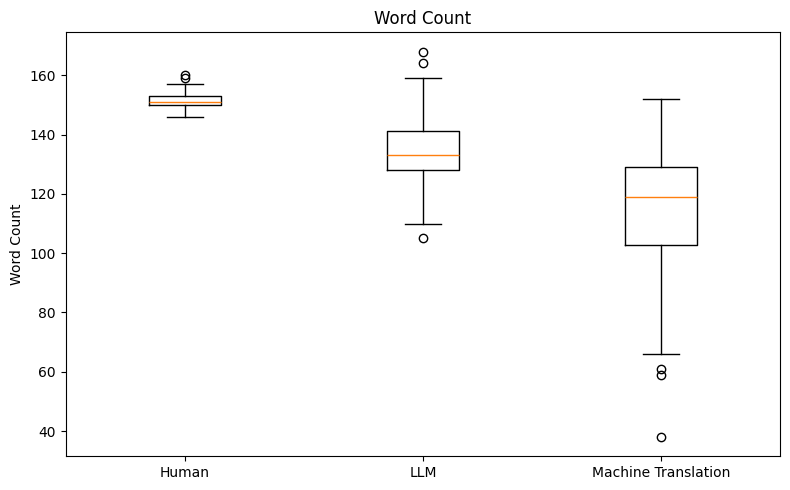

/tmp/ipykernel_49/482383295.py:30: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


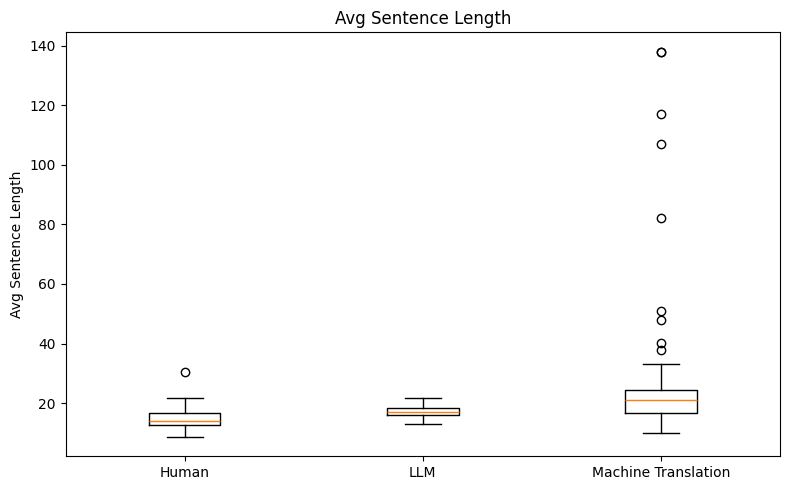

/tmp/ipykernel_49/482383295.py:30: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


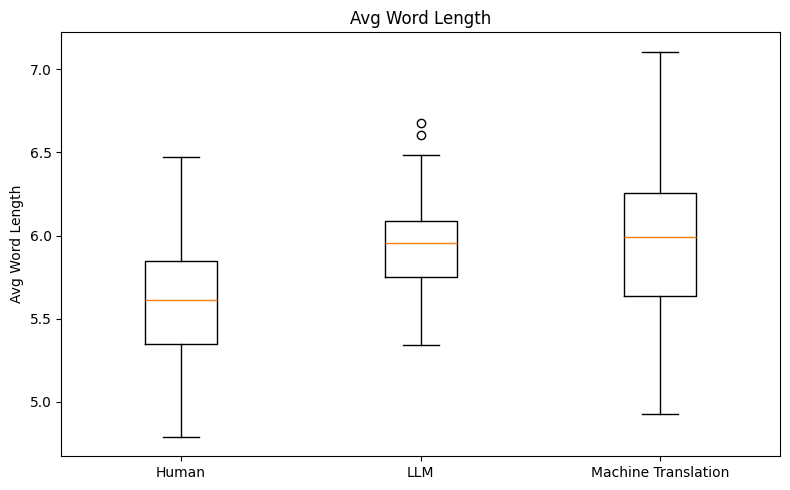

/tmp/ipykernel_49/482383295.py:30: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


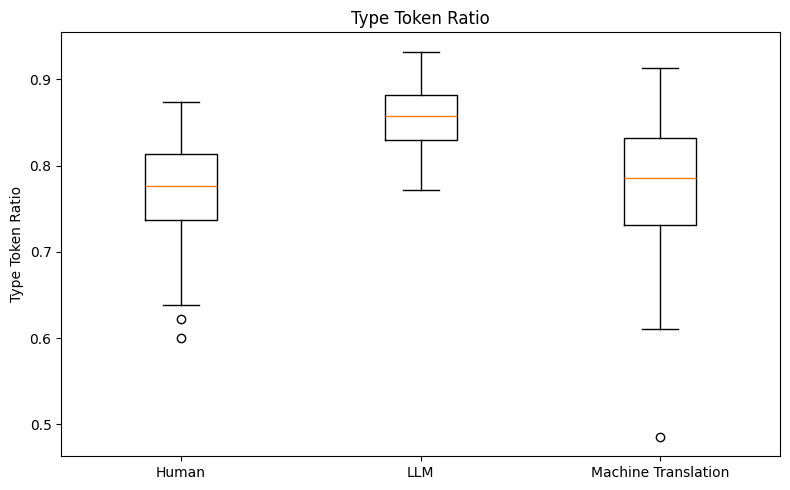

/tmp/ipykernel_49/482383295.py:30: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


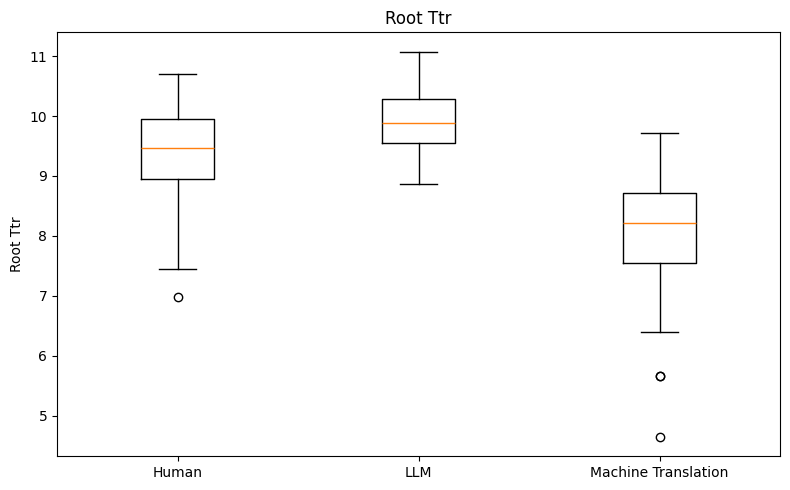

/tmp/ipykernel_49/482383295.py:30: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


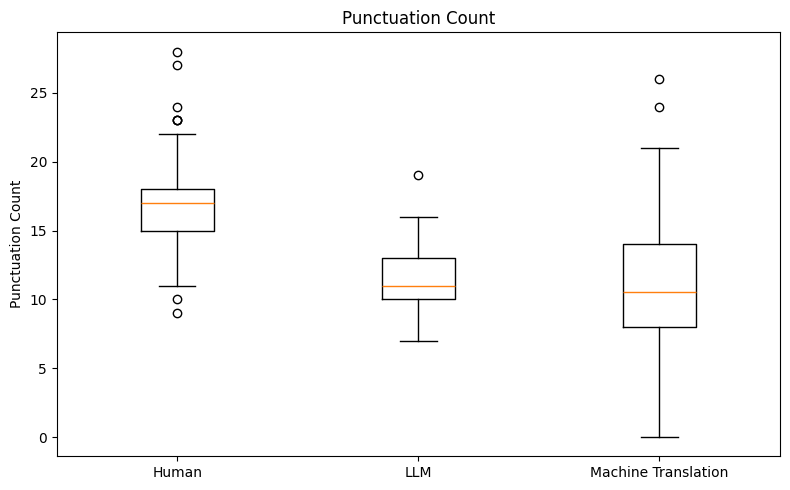

/tmp/ipykernel_49/482383295.py:30: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


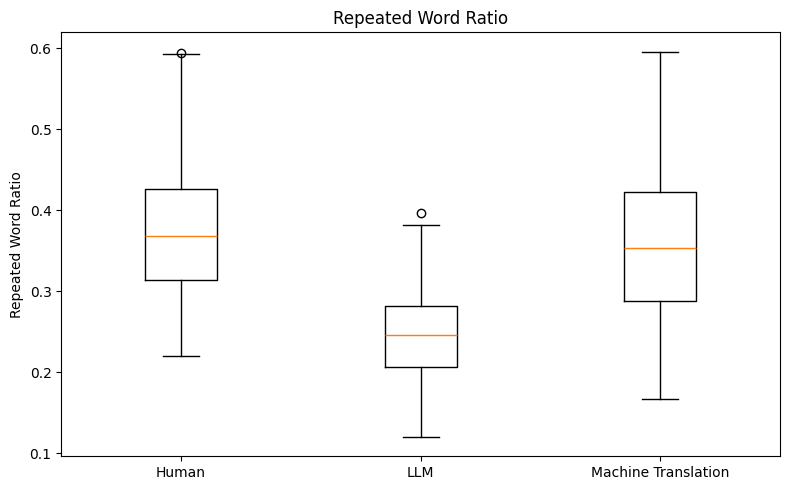

/tmp/ipykernel_49/482383295.py:30: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


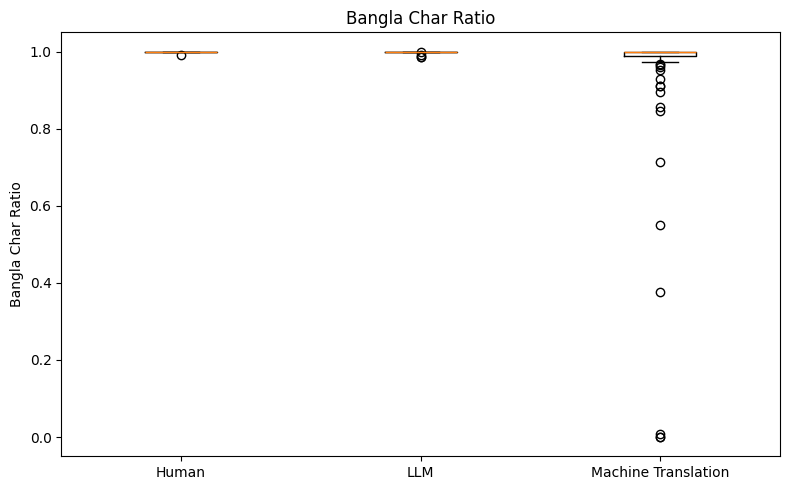

In [8]:
import matplotlib.pyplot as plt

plot_features = [
    "word_count",
    "avg_sentence_length",
    "avg_word_length",
    "type_token_ratio",
    "root_ttr",
    "punctuation_count",
    "repeated_word_ratio",
    "bangla_char_ratio"
]

for feature in plot_features:

    plt.figure(figsize=(8, 5))

    data = [
        features_df.loc[
            features_df["condition"] == condition,
            feature
        ]
        for condition in [
            "human",
            "llm",
            "machine_translation"
        ]
    ]

    plt.boxplot(
        data,
        labels=["Human", "LLM", "Machine Translation"]
    )

    plt.title(f"{feature.replace('_', ' ').title()}")
    plt.ylabel(feature.replace("_", " ").title())
    plt.tight_layout()
    plt.show()

In [9]:
import plotly.express as px

plot_features = [
    "word_count",
    "sentence_count",
    "avg_sentence_length",
    "avg_word_length",
    "type_token_ratio",
    "repeated_word_ratio"
]

feature_names = {
    "word_count": "Word Count",
    "sentence_count": "Sentence Count",
    "avg_sentence_length": "Average Sentence Length",
    "avg_word_length": "Average Word Length",
    "type_token_ratio": "Type-Token Ratio",
    "repeated_word_ratio": "Repeated Word Ratio"
}

for feature in plot_features:

    fig = px.violin(
        features_df,
        x="condition",
        y=feature,
        color="condition",
        box=True,
        points=False,
        title=feature_names[feature]
    )

    fig.update_layout(
        template="plotly_white",
        height=500,
        width=900,
        showlegend=False,
        xaxis_title="Text Condition",
        yaxis_title=feature_names[feature]
    )

    fig.show(renderer="iframe")

In [10]:
print(effect_results.columns.tolist())

['feature', 'comparison', 'bonferroni_p', 'rank_biserial_r', 'absolute_effect']


In [11]:
import plotly.express as px

effect_plot = effect_results.copy()

# Keep statistically significant comparisons
effect_plot = effect_plot[
    effect_plot["bonferroni_p"] < 0.05
].copy()

# Keep the 15 largest effects
effect_plot = (
    effect_plot
    .sort_values("absolute_effect", ascending=False)
    .head(15)
)

# Shorter feature names
effect_plot["feature"] = (
    effect_plot["feature"]
    .str.replace("_", " ", regex=False)
    .str.title()
)

fig = px.bar(
    effect_plot.sort_values("rank_biserial_r"),
    x="rank_biserial_r",
    y="feature",
    color="comparison",
    orientation="h",
    hover_data=["bonferroni_p"],
    title="Largest Pairwise Stylometric Effect Sizes"
)

fig.update_layout(
    template="plotly_white",
    height=700,
    width=1000,
    xaxis_title="Rank-Biserial Effect Size",
    yaxis_title="Feature",
    legend_title="Comparison"
)

fig.add_vline(
    x=0,
    line_width=1
)

fig.show(renderer="iframe")

In [12]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import pandas as pd
import plotly.express as px

# Features used for PCA
pca_features = [
    "word_count",
    "sentence_count",
    "avg_sentence_length",
    "avg_word_length",
    "unique_word_count",
    "type_token_ratio",
    "root_ttr",
    "char_count",
    "punctuation_count",
    "comma_count",
    "fullstop_count",
    "question_count",
    "exclamation_count",
    "digit_count",
    "bangla_char_ratio",
    "repeated_word_ratio"
]

# Standardize features
X = features_df[pca_features]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# Create PCA dataframe
pca_df = pd.DataFrame({
    "PC1": X_pca[:, 0],
    "PC2": X_pca[:, 1],
    "condition": features_df["condition"],
    "topic_id": features_df["topic_id"],
    "topic": features_df["topic"]
})

print("Explained variance:")
print("PC1:", round(pca.explained_variance_ratio_[0] * 100, 2), "%")
print("PC2:", round(pca.explained_variance_ratio_[1] * 100, 2), "%")
print(
    "Total:",
    round(pca.explained_variance_ratio_[:2].sum() * 100, 2),
    "%"
)

fig = px.scatter(
    pca_df,
    x="PC1",
    y="PC2",
    color="condition",
    hover_data=["topic_id", "topic"],
    title="PCA of Stylometric Features"
)

fig.update_layout(
    template="plotly_white",
    width=950,
    height=650
)

fig.show(renderer="iframe")

Explained variance:
PC1: 34.35 %
PC2: 18.89 %
Total: 53.24 %


In [13]:
import plotly.express as px

corr_features = [
    "word_count",
    "sentence_count",
    "avg_sentence_length",
    "avg_word_length",
    "unique_word_count",
    "type_token_ratio",
    "root_ttr",
    "char_count",
    "punctuation_count",
    "comma_count",
    "fullstop_count",
    "question_count",
    "exclamation_count",
    "digit_count",
    "bangla_char_ratio",
    "repeated_word_ratio"
]

corr_matrix = features_df[corr_features].corr()

fig = px.imshow(
    corr_matrix,
    text_auto=".2f",
    aspect="auto",
    title="Correlation Between Stylometric Features",
    color_continuous_scale="RdBu_r",
    zmin=-1,
    zmax=1
)

fig.update_layout(
    width=950,
    height=850
)

fig.show(renderer="iframe")

In [14]:
import os
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# ============================================================
# POSTER FIGURES
# ============================================================

output_dir = "/kaggle/working/poster_figures"
os.makedirs(output_dir, exist_ok=True)

# ------------------------------------------------------------
# 1. FEATURE DISTRIBUTIONS
# ------------------------------------------------------------

poster_features = [
    ("word_count", "Word Count"),
    ("avg_sentence_length", "Average Sentence Length"),
    ("repeated_word_ratio", "Repeated Word Ratio")
]

for feature, title in poster_features:

    plt.figure(figsize=(9, 6))

    sns.violinplot(
        data=features_df,
        x="condition",
        y=feature,
        inner="box"
    )

    plt.title(title, fontsize=16, fontweight="bold")
    plt.xlabel("Text Condition", fontsize=12)
    plt.ylabel(title, fontsize=12)
    plt.xticks(
        ticks=[0, 1, 2],
        labels=["Human", "LLM", "Machine Translation"]
    )

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            output_dir,
            f"{feature}_distribution.png"
        ),
        dpi=300,
        bbox_inches="tight"
    )

    plt.close()


# ------------------------------------------------------------
# 2. EFFECT SIZE PLOT
# ------------------------------------------------------------

effect_plot = effect_results.copy()

effect_plot = effect_plot[
    effect_plot["bonferroni_p"] < 0.05
].copy()

effect_plot = (
    effect_plot
    .sort_values("absolute_effect", ascending=False)
    .head(15)
)

# Make readable labels
effect_plot["feature_label"] = (
    effect_plot["feature"]
    .str.replace("_", " ", regex=False)
    .str.title()
)

effect_plot["comparison_label"] = (
    effect_plot["comparison"]
    .str.replace("_", " ", regex=False)
    .str.title()
)

plt.figure(figsize=(10, 8))

sns.barplot(
    data=effect_plot.sort_values("rank_biserial_r"),
    x="rank_biserial_r",
    y="feature_label",
    hue="comparison_label"
)

plt.axvline(
    0,
    linewidth=1
)

plt.title(
    "Largest Pairwise Stylometric Effect Sizes",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Rank-Biserial Effect Size", fontsize=12)
plt.ylabel("Feature", fontsize=12)

plt.legend(
    title="Comparison",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        output_dir,
        "effect_sizes.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.close()


# ------------------------------------------------------------
# 3. PCA PLOT
# ------------------------------------------------------------

pca_features = [
    "word_count",
    "sentence_count",
    "avg_sentence_length",
    "avg_word_length",
    "unique_word_count",
    "type_token_ratio",
    "root_ttr",
    "char_count",
    "punctuation_count",
    "comma_count",
    "fullstop_count",
    "question_count",
    "exclamation_count",
    "digit_count",
    "bangla_char_ratio",
    "repeated_word_ratio"
]

X = features_df[pca_features]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

pca_plot_df = features_df[
    ["condition", "topic_id"]
].copy()

pca_plot_df["PC1"] = X_pca[:, 0]
pca_plot_df["PC2"] = X_pca[:, 1]

plt.figure(figsize=(9, 7))

sns.scatterplot(
    data=pca_plot_df,
    x="PC1",
    y="PC2",
    hue="condition",
    s=65,
    alpha=0.8
)

pc1 = pca.explained_variance_ratio_[0] * 100
pc2 = pca.explained_variance_ratio_[1] * 100

plt.xlabel(f"PC1 ({pc1:.2f}% variance)", fontsize=12)
plt.ylabel(f"PC2 ({pc2:.2f}% variance)", fontsize=12)

plt.title(
    "PCA of Stylometric Features",
    fontsize=16,
    fontweight="bold"
)

plt.legend(
    title="Text Condition"
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        output_dir,
        "pca_stylometry.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.close()


# ------------------------------------------------------------
# 4. CORRELATION HEATMAP
# ------------------------------------------------------------

corr_features = [
    "word_count",
    "sentence_count",
    "avg_sentence_length",
    "avg_word_length",
    "unique_word_count",
    "type_token_ratio",
    "root_ttr",
    "char_count",
    "punctuation_count",
    "comma_count",
    "fullstop_count",
    "question_count",
    "exclamation_count",
    "digit_count",
    "bangla_char_ratio",
    "repeated_word_ratio"
]

corr_matrix = features_df[corr_features].corr()

plt.figure(figsize=(14, 11))

sns.heatmap(
    corr_matrix,
    cmap="RdBu_r",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.3,
    cbar_kws={"label": "Pearson Correlation"}
)

plt.title(
    "Correlation Between Stylometric Features",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        output_dir,
        "feature_correlation_heatmap.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.close()


# ------------------------------------------------------------
# FINAL CHECK
# ------------------------------------------------------------

print("Poster figures generated successfully:")
print()

for filename in sorted(os.listdir(output_dir)):
    path = os.path.join(output_dir, filename)
    size_kb = os.path.getsize(path) / 1024
    print(f"{filename:40s} {size_kb:.1f} KB")

print()
print("Saved to:")
print(output_dir)

Poster figures generated successfully:

avg_sentence_length_distribution.png     127.1 KB
effect_sizes.png                         185.5 KB
feature_correlation_heatmap.png          350.9 KB
pca_stylometry.png                       408.5 KB
repeated_word_ratio_distribution.png     191.0 KB
word_count_distribution.png              119.6 KB

Saved to:
/kaggle/working/poster_figures


In [15]:

import pandas as pd
import numpy as np
from scipy.stats import kruskal, mannwhitneyu
from itertools import combinations
from statsmodels.stats.multitest import multipletests

# The 16 stylometric features
features = [
    "word_count",
    "sentence_count",
    "avg_sentence_length",
    "avg_word_length",
    "unique_word_count",
    "type_token_ratio",
    "root_ttr",
    "char_count",
    "punctuation_count",
    "comma_count",
    "fullstop_count",
    "question_count",
    "exclamation_count",
    "digit_count",
    "bangla_char_ratio",
    "repeated_word_ratio"
]

conditions = ["human", "llm", "machine_translation"]

# Check that the required columns exist
required = ["topic_id", "condition"] + features
missing = [col for col in required if col not in features_df.columns]

if missing:
    raise ValueError(f"Missing columns in features_df: {missing}")

# Check group sizes
print("Number of texts per condition:")
print(features_df["condition"].value_counts())

# Check missing values
print("\nMissing values in features:")
print(features_df[features].isna().sum().sum())

# --------------------------------------------------
# A. KRUSKAL-WALLIS TESTS
# --------------------------------------------------

kw_results = []

for feature in features:
    groups = [
        features_df.loc[
            features_df["condition"] == condition, feature
        ].dropna()
        for condition in conditions
    ]

    statistic, p_value = kruskal(*groups)

    kw_results.append({
        "feature": feature,
        "H_statistic": statistic,
        "p_value": p_value
    })

kw_df = pd.DataFrame(kw_results)
kw_df["significant_p_lt_05"] = kw_df["p_value"] < 0.05

print("\n=== KRUSKAL-WALLIS RESULTS ===")
print(kw_df.to_string(index=False, float_format=lambda x: f"{x:.6g}"))

# --------------------------------------------------
# B. PAIRWISE MANN-WHITNEY U TESTS
#    Bonferroni correction within each feature
# --------------------------------------------------

pair_results = []
pairs = list(combinations(conditions, 2))

for feature in features:
    raw_p_values = []
    pair_details = []

    for group_a, group_b in pairs:
        a = features_df.loc[
            features_df["condition"] == group_a, feature
        ].dropna()

        b = features_df.loc[
            features_df["condition"] == group_b, feature
        ].dropna()

        result = mannwhitneyu(
            a, b,
            alternative="two-sided",
            method="auto"
        )

        # Rank-biserial correlation based on U
        # Positive means values tend to be larger in group A
        # than group B.
        n_a, n_b = len(a), len(b)
        rank_biserial = 2 * result.statistic / (n_a * n_b) - 1

        raw_p_values.append(result.pvalue)

        pair_details.append({
            "feature": feature,
            "group_a": group_a,
            "group_b": group_b,
            "n_a": n_a,
            "n_b": n_b,
            "U_statistic": result.statistic,
            "p_raw": result.pvalue,
            "rank_biserial": rank_biserial
        })

    # Correct the three pairwise tests for this feature
    adjusted_p_values = multipletests(
        raw_p_values, method="bonferroni"
    )[1]

    for details, adjusted_p in zip(pair_details, adjusted_p_values):
        details["p_bonferroni"] = adjusted_p
        details["significant_p_lt_05"] = adjusted_p < 0.05
        pair_results.append(details)

pairwise_df = pd.DataFrame(pair_results)

print("\n=== PAIRWISE MANN-WHITNEY + BONFERRONI + RANK-BISERIAL ===")
print(
    pairwise_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.6g}"
    )
)

# --------------------------------------------------
# C. SUMMARY OF SIGNIFICANT RESULTS
# --------------------------------------------------

print("\n=== KRUSKAL-WALLIS SIGNIFICANCE SUMMARY ===")
print(
    f"Significant features: "
    f"{kw_df['significant_p_lt_05'].sum()} / {len(features)}"
)

print("\n=== PAIRWISE SIGNIFICANCE COUNTS ===")
print(
    pairwise_df.groupby(["group_a", "group_b"])[
        "significant_p_lt_05"
    ].agg(["sum", "count"])
)

# --------------------------------------------------
# D. SAVE TABLES
# --------------------------------------------------

kw_df.to_csv("kruskal_wallis_results.csv", index=False)
pairwise_df.to_csv("pairwise_mann_whitney_results.csv", index=False)

print("\nSaved:")
print("kruskal_wallis_results.csv")
print("pairwise_mann_whitney_results.csv")

Number of texts per condition:
condition
human                  100
llm                    100
machine_translation    100
Name: count, dtype: int64

Missing values in features:
0

=== KRUSKAL-WALLIS RESULTS ===
            feature  H_statistic     p_value  significant_p_lt_05
         word_count      196.806  1.8373e-43                 True
     sentence_count       165.33 1.25593e-36                 True
avg_sentence_length      86.7523 1.45205e-19                 True
    avg_word_length      43.1929 4.17618e-10                 True
  unique_word_count      165.902 9.43601e-37                 True
   type_token_ratio      112.312 4.09028e-25                 True
           root_ttr      161.954 6.79337e-36                 True
         char_count      134.072 7.70182e-30                 True
  punctuation_count      120.849 5.72643e-27                 True
        comma_count      36.3624 1.27059e-08                 True
     fullstop_count        174.9 1.04929e-38                 Tr